# Thematic Clustering of GDPR Projects
TF-IDF on project descriptions → dimensionality reduction → clustering

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 150

In [ ]:
df = pd.read_csv('gdpr_projects.csv')
df['start_date'] = pd.to_datetime(df['start_date'])
df['end_date'] = pd.to_datetime(df['end_date'])
df['duration_months'] = ((df['end_date'] - df['start_date']).dt.days / 30.44).round(0).astype(int)
df['start_year'] = df['start_date'].dt.year
print(f'{len(df)} projects loaded')
df[['project_name', 'description', 'funding_eur']].head()

31 projects loaded


,project_name,description,funding_eur
0,smashHit,Smart Sharing of Health and Industry Data via ...,4500000.0
1,Odlaw,Retroactive Data Protection Compliance Tool fo...,NaN
2,RuleKeeper,GDPR-Aware Personal Data Compliance for Web Fr...,NaN
3,PDP4E,Privacy and Data Protection Tools for Engineer...,4200000.0
4,SPECIAL,Scalable Policy-aware Linked Data Architecture...,4400000.0


## 1. TF-IDF Vectorization
 description + keywords + domain into a single text field for richer features

In [8]:
df['text'] = (
    df['description'].fillna('') + ' ' +
    df['keywords'].fillna('') + ' ' +
    df['domain'].fillna('')
)

tfidf = TfidfVectorizer(
    max_features=100,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2
)
X = tfidf.fit_transform(df['text'])
print(f'TF-IDF matrix: {X.shape}')
print(f'Top terms: {tfidf.get_feature_names_out()[:20]}')

TF-IDF matrix: (31, 100)
Top terms: ['analytics' 'analytics data' 'assessment' 'aware' 'awareness'
 'awareness gdpr' 'based' 'blockchain' 'border' 'business'
 'business compliance' 'cities' 'compliance' 'compliance healthcare'
 'compliance smes' 'compliance tool' 'compliance web' 'compliant' 'cross'
 'cross border']


## 2. Hierarchical Clustering (Dendrogram)



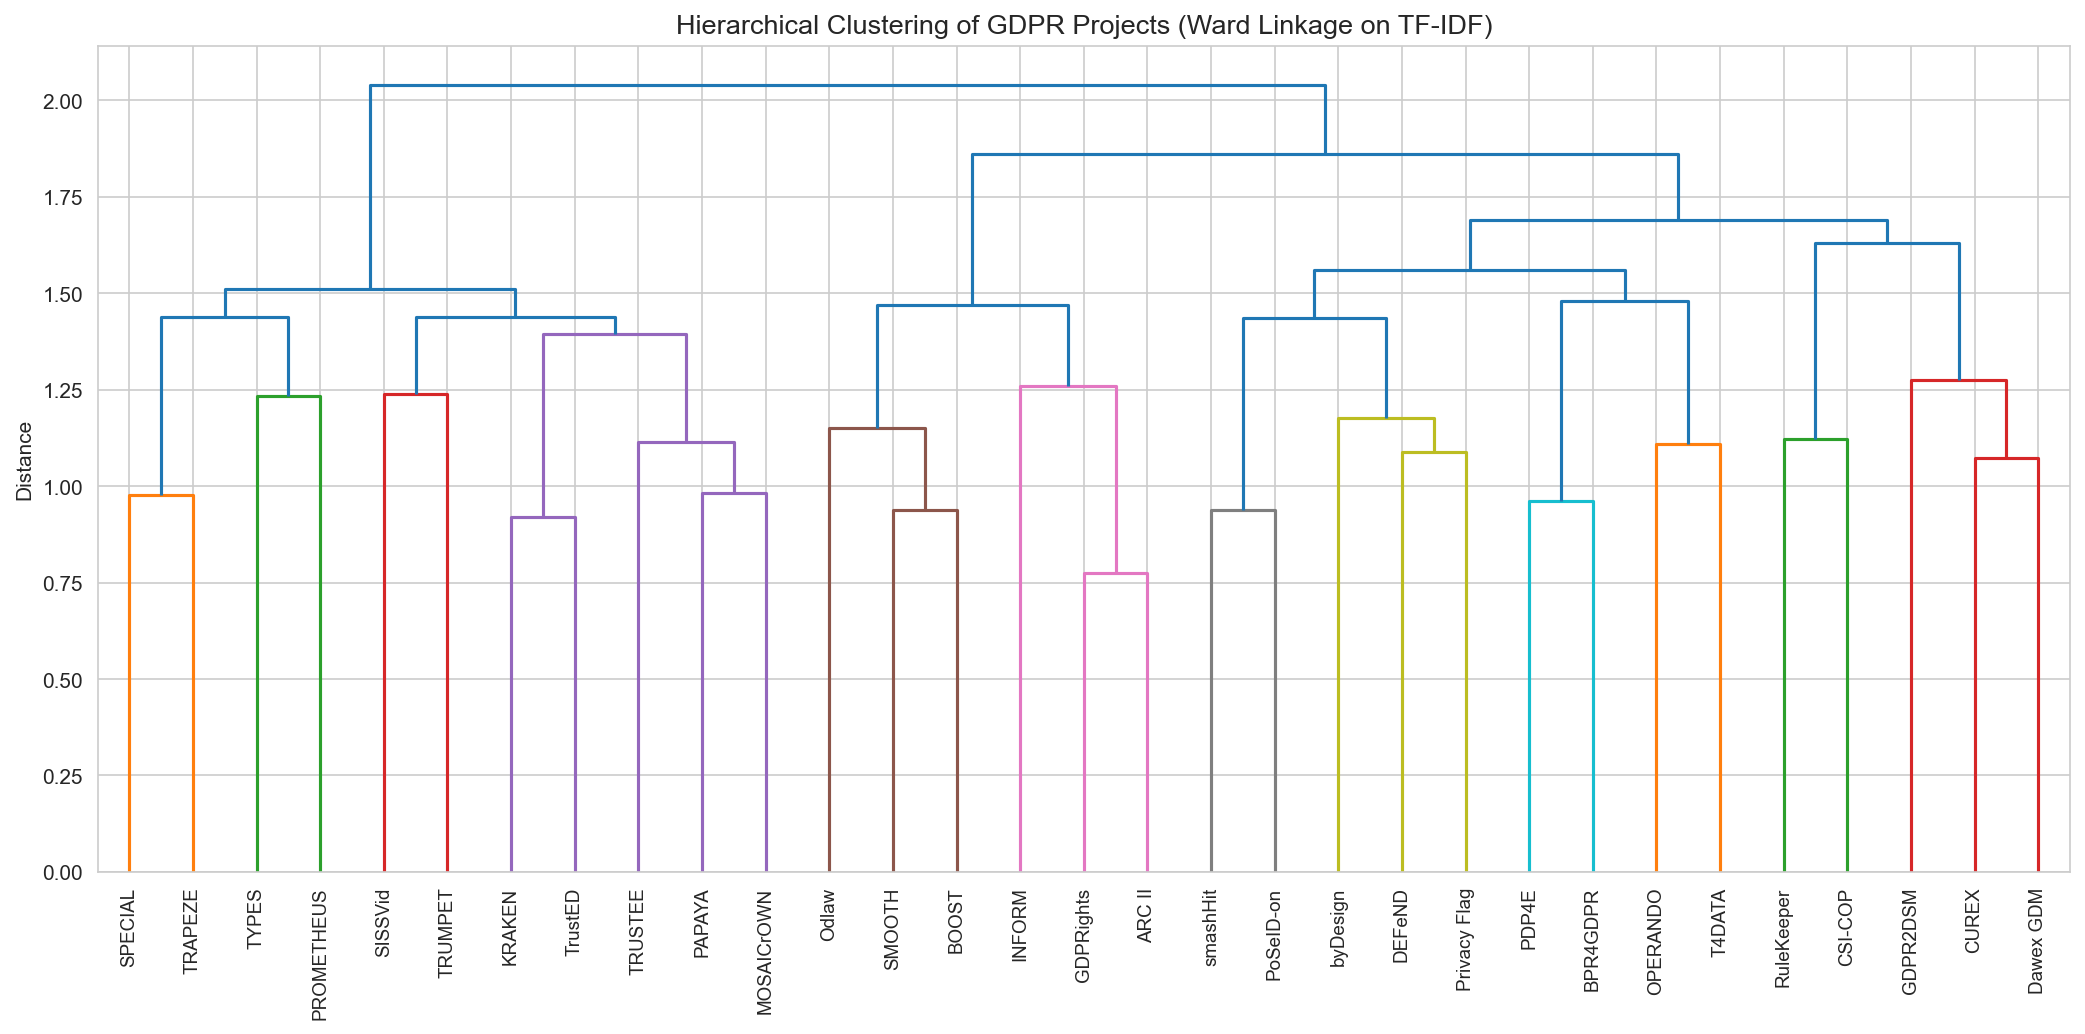

In [9]:
Z = linkage(X.toarray(), method='ward', metric='euclidean')

fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(
    Z,
    labels=df['project_name'].values,
    leaf_rotation=90,
    leaf_font_size=9,
    ax=ax
)
ax.set_title('Hierarchical Clustering of GDPR Projects (Ward Linkage on TF-IDF)', fontsize=13)
ax.set_ylabel('Distance')
plt.tight_layout()
plt.savefig('dendrogram.png', bbox_inches='tight')
plt.show()

## 3. Determine Optimal k (Silhouette Scores)

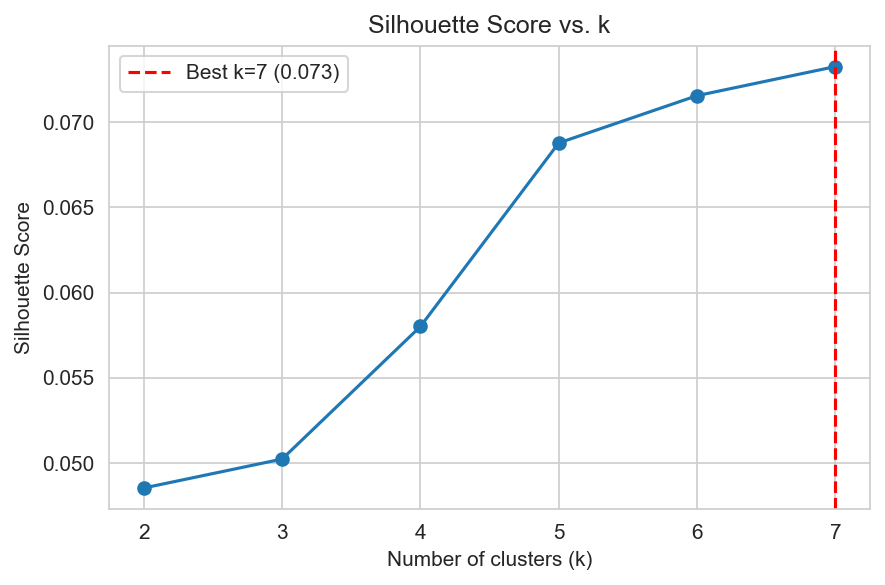

Best k = 7, silhouette = 0.073


In [10]:
X_dense = X.toarray()
sil_scores = {}
for k in range(2, 8):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_dense)
    sil_scores[k] = silhouette_score(X_dense, labels)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(sil_scores.keys()), list(sil_scores.values()), 'o-')
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette Score vs. k')
best_k = max(sil_scores, key=sil_scores.get)
ax.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k} ({sil_scores[best_k]:.3f})')
ax.legend()
plt.tight_layout()
plt.savefig('silhouette_scores.png', bbox_inches='tight')
plt.show()
print(f'Best k = {best_k}, silhouette = {sil_scores[best_k]:.3f}')

## 4. Assign Clusters & Visualize with PCA

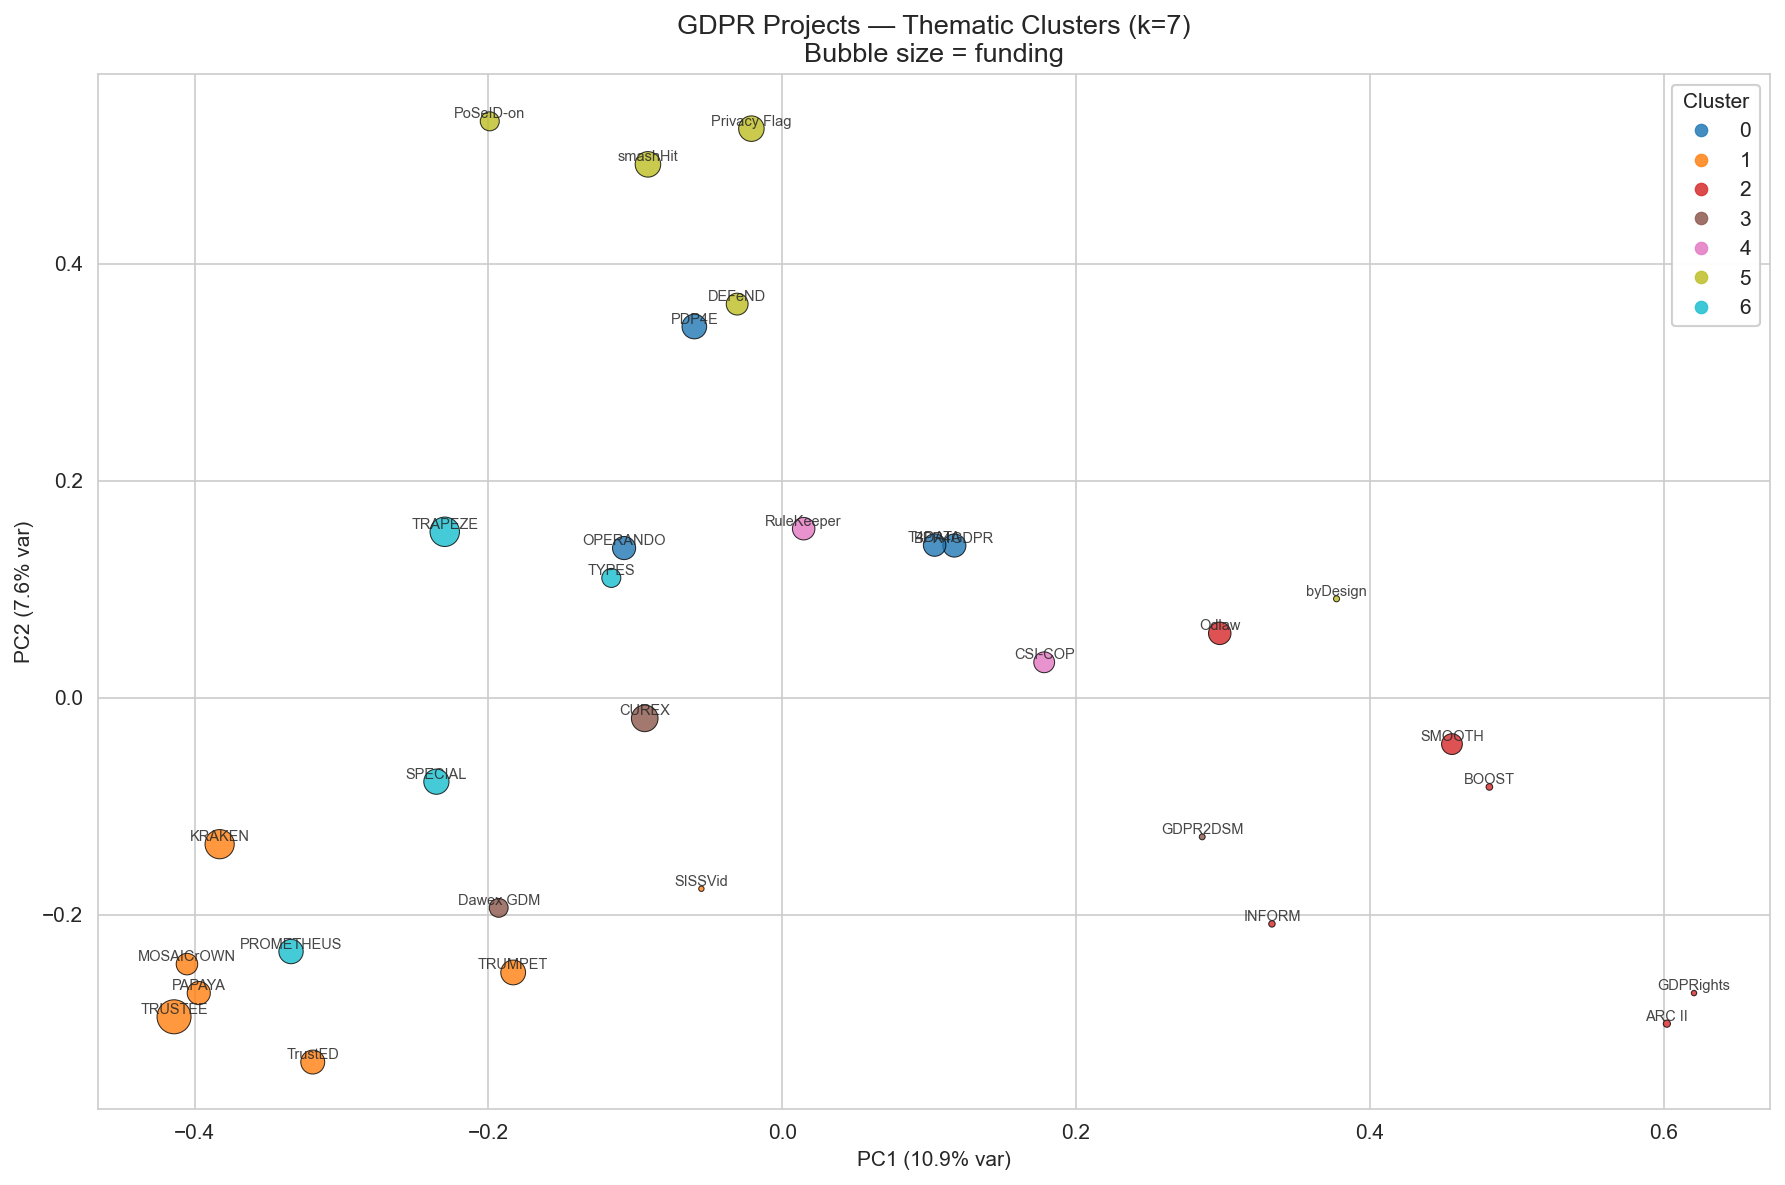

In [14]:
df['cluster'] = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X_dense)
pca = PCA(n_components=2)
coords = pca.fit_transform(X_dense)
df['pca_x'] = coords[:, 0]
df['pca_y'] = coords[:, 1]

fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(
    df['pca_x'], df['pca_y'],
    c=df['cluster'],
    s=df['funding_eur'].fillna(df['funding_eur'].median()) / 30000,
    cmap='tab10',
    alpha=0.8,
    edgecolors='black',
    linewidth=0.5
)
for _, row in df.iterrows():
    ax.annotate(row['project_name'], (row['pca_x'], row['pca_y']),
                fontsize=7, ha='center', va='bottom', alpha=0.85)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} var)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} var)')
ax.set_title(f'GDPR Projects — Thematic Clusters (k={best_k})\nBubble size = funding', fontsize=13)
legend1 = ax.legend(*scatter.legend_elements(), title='Cluster', loc='upper right')
ax.add_artist(legend1)
plt.tight_layout()
plt.savefig('thematic_clusters_pca.png', bbox_inches='tight')
plt.show()

## 5. Cluster Summary: Top Terms & Funding Stats

In [12]:
feature_names = tfidf.get_feature_names_out()

for c in sorted(df['cluster'].unique()):
    mask = (df['cluster'] == c).values  # numpy array for sparse indexing
    cluster_projects = df.loc[mask, 'project_name'].tolist()
    cluster_funding = df.loc[mask, 'funding_eur'].dropna()
    
    # Top TF-IDF terms for this cluster
    cluster_tfidf_mean = X[mask].toarray().mean(axis=0)
    top_idx = cluster_tfidf_mean.argsort()[-8:][::-1]
    top_terms = [feature_names[i] for i in top_idx]
    
    print(f'\n=== Cluster {c} ({mask.sum()} projects) ===')
    print(f'Projects: {", ".join(cluster_projects)}')
    print(f'Top terms: {", ".join(top_terms)}')
    if len(cluster_funding) > 0:
        print(f'Funding — mean: €{cluster_funding.mean():,.0f}, '
              f'median: €{cluster_funding.median():,.0f}, '
              f'range: €{cluster_funding.min():,.0f}–€{cluster_funding.max():,.0f}')
    else:
        print('Funding — no data')


=== Cluster 0 (4 projects) ===
Projects: PDP4E, BPR4GDPR, OPERANDO, T4DATA
Top terms: engineering, public, privacy, data protection, protection, healthcare, compliance healthcare, business
Funding — mean: €3,866,667, median: €3,700,000, range: €3,700,000–€4,200,000

=== Cluster 1 (7 projects) ===
Projects: TRUSTEE, PAPAYA, MOSAICrOWN, KRAKEN, SISSVid, TRUMPET, TrustED
Top terms: data, privacy, encryption, privacy preserving, preserving, analytics, healthcare, data sharing
Funding — mean: €4,171,864, median: €3,960,000, range: €199,700–€8,000,000

=== Cluster 2 (6 projects) ===
Projects: Odlaw, INFORM, SMOOTH, BOOST, GDPRights, ARC II
Top terms: compliance, smes, awareness, gdpr, tool, training, gdpr compliance, gdpr awareness
Funding — mean: €829,702, median: €305,410, range: €202,600–€2,990,000

=== Cluster 3 (3 projects) ===
Projects: CUREX, Dawex GDM, GDPR2DSM
Top terms: data, data exchange, exchange, single market, market, digital single, single, digital
Funding — mean: €2,533,667

## 6. Cluster × Funding Boxplot

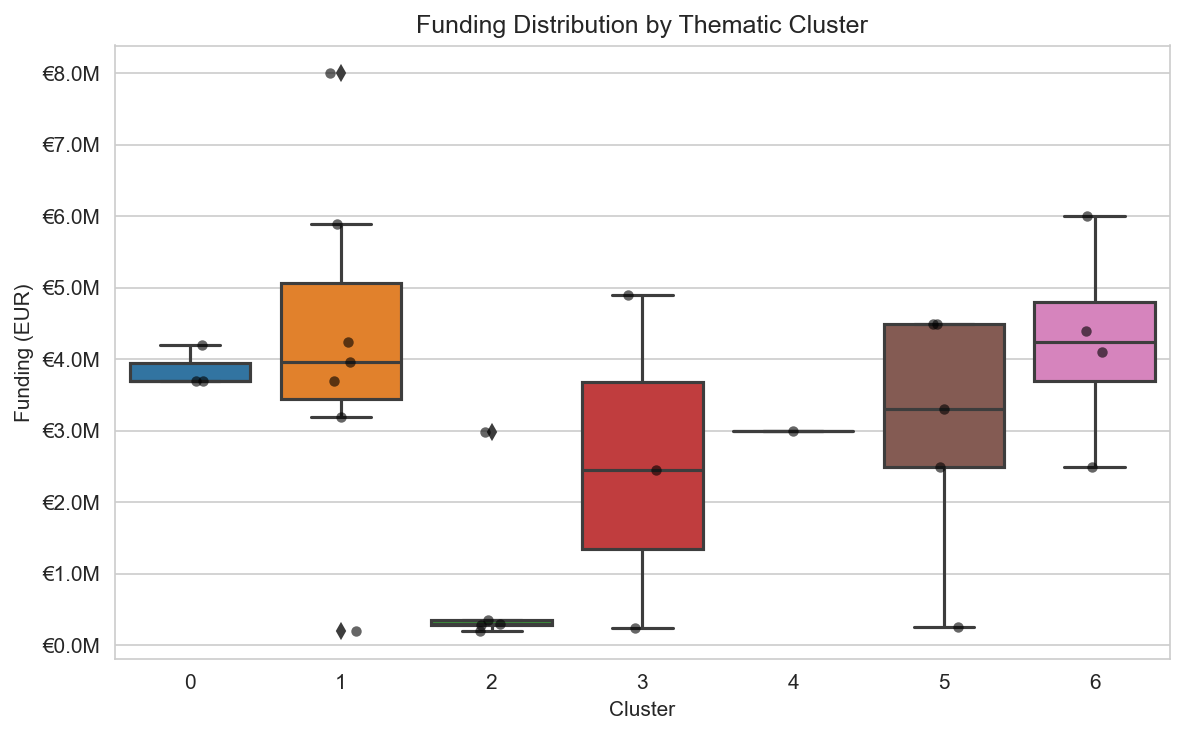

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
df_funded = df.dropna(subset=['funding_eur'])
sns.boxplot(data=df_funded, x='cluster', y='funding_eur', ax=ax, palette='tab10')
sns.stripplot(data=df_funded, x='cluster', y='funding_eur', ax=ax, color='black', size=5, alpha=0.6)
ax.set_ylabel('Funding (EUR)')
ax.set_xlabel('Cluster')
ax.set_title('Funding Distribution by Thematic Cluster')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'€{x/1e6:.1f}M'))
plt.tight_layout()
plt.savefig('cluster_funding_boxplot.png', bbox_inches='tight')
plt.show()